In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint
import pickle

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
from sklearn.decomposition import PCA
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score

import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.14.8 (main, Oct  1 2026, 19:55:55) [GCC 16.2.0]


In [2]:
def plot_params(lfm, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = lfm.n_input
    mask = np.zeros(n, np.uint8)
    for mod in lfm.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        mask = mask | (abs(param1) > p_threshold)
        ax.vlines(range(mod.n_input), param_m, param_p, color='k')
    ax.minorticks_on()
    s = mask.astype("i").sum()
    plt.title(f'Значения коэффициентов классификатора:  #(abs(param) > {p_threshold}) = {s}')

def plot_param(param, p_threshold=1.0e-4):
    ax = plt.twinx(plt.gca())
    n = len(param)
    param_p = param.copy()
    param_m = param.copy()
    param_p[param < 0] = 0
    param_m[param > 0] = 0
    ax.vlines(range(n), param_m, param_p, color='k')
    ax.minorticks_on()
    if p_threshold != 0:
        mask = (abs(param) > p_threshold)
        s = mask.astype("i").sum()
        plt.title(f'#(abs(param) > {p_threshold}) = {s}')

In [3]:
def rescale_by(X, Y):
    mu_y = np.median(Y, axis=0)
    sigma_y = np.median(abs(Y - mu_y))
    mu_x = np.median(X, axis=0)
    sigma_x = np.median(abs(X - mu_x))
    return (X - mu_x) / sigma_x * sigma_y + mu_y
    

In [4]:
def plot_pca(xs, Ys, labels, colors=None, markers=None, kind="l2/l2", 
             q=1.0, m=5, mm=3, n_iter=200, tol=1.0e-6, verbose=False, 
             plot_reconstructed=False, plot_eigenval=False, plot_eigenvec=False,
             return_result=False):

    Y = np.vstack(Ys)
    c, As, Ls = pca.find_loc_pc_sv(Y, m, n_iter=n_iter, tol=tol, verbose=verbose, q=q)
    Us = [pca.transform(ys, c, As) for ys in Ys]

    plt.figure(figsize=(15,5))
    for i in range(mm):
        plt.subplot(1,mm,i+1)
        if colors is None:
            for U, label in zip(Us, labels):
                plt.scatter(U[:,i], U[:,i+1], s=25, edgecolors='k', linewidth=0.5, label=label)
        else:
            if markers is None:
                for U, label, color in zip(Us, labels, colors):
                    plt.scatter(U[:,i], U[:,i+1], s=25, c=color, edgecolors='k', linewidth=0.5, label=label)
            else:
                for U, label, color, marker in zip(Us, labels, colors, markers):
                    plt.scatter(U[:,i], U[:,i+1], s=25, c=color, marker=marker, edgecolors='k', linewidth=0.5, label=label)
        plt.xlabel(str(i+1))
        plt.ylabel(str(i+2))
        plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()

    if plot_reconstructed:
        plt.figure(figsize=(12,5))
        plt.title("Reconstruction from PCs")
        for U, label in zip(Us, labels):
            plt.plot(xs, (U @ As + c).mean(axis=0), label=label)
        plt.tight_layout()
        plt.minorticks_on()
        plt.legend()
        plt.show()

    Ls /= Ls.sum()

    if plot_eigenvec:
        plt.figure(figsize=(12,6))
        for i,a in enumerate(As[:10]):
            plt.plot(xs, a*Ls[i], label=str(i+1))
        plt.ylabel("PCs")
        plt.legend()
    
        plt.minorticks_on()
        plt.grid(lw=0.5, ls=':')
        plt.tight_layout()
        plt.show()
    
    if plot_eigenval:
        plt.figure(figsize=(10,3))
        plt.title("Собственные числа")
        plt.plot(Ls, marker='o', ms=2)
        plt.yscale('log')
        plt.xscale('log')
        plt.grid(ls=':', lw=0.5)
        plt.ylabel(r"$\log\lambda$")
        plt.minorticks_on()
        plt.show()

    if return_result:
        return c, As


In [5]:
def plot_pca_raw(Ys):
    c, As, Ls = pca.find_loc_and_pc(Ys, 10)
    U = (Ys - c) @ As.T
    plt.figure(figsize=(15,4))
    for i in range(4):
        plt.subplot(1,4,i+1)
        plt.scatter(U[:,i], U[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="Raw")
        plt.xlabel(f"PC {str(i+1)}")
        plt.ylabel(f"PC {str(i+2)}")
        # plt.xticks([])
        # plt.yticks([])
        plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()
    
    plt.figure(figsize=(10,3))
    plt.title("Собственные числа")
    plt.plot(Ls/Ls.sum(), marker='o')
    plt.grid(ls=':', lw=0.5)
    plt.minorticks_on()
    plt.show()

In [6]:
def plot_robust_pca(Ys_SS, Ys_SA, Ys_SH, wma):
    Ys = np.vstack((Ys_SS, Ys_SA, Ys_SH))
    # c = np.zeros_like(Ys[0])
    # As, Ls = pca.find_pc_all(Ys, 5)
    c, As, Ls = pca.find_robust_loc_and_pc(Ys, wma, 10)
    U = pca.transform(Ys, c, As)
    U_SA = pca.transform(Ys_SA, c, As)
    U_SS = pca.transform(Ys_SS, c, As)
    U_SH = pca.transform(Ys_SH, c, As)
    plt.figure(figsize=(15,4))
    for i in range(4):
        plt.subplot(1,4,i+1)
        plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
        plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
        plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
        plt.xlabel(f"PC {str(i+1)}")
        plt.ylabel(f"PC {str(i+2)}")
        # plt.xticks([])
        # plt.yticks([])
        plt.legend()
    plt.tight_layout()
    plt.legend()
    plt.show()

    Ls /= Ls.sum()
    
    plt.figure(figsize=(12,4))
    for i,a in enumerate(As):
        plt.plot(a, label=str(i+1))
    plt.minorticks_on()
    plt.grid(lw=0.5, ls=':')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10,3))
    plt.title("Собственные числа")
    plt.plot(Ls, marker='o')
    plt.grid(ls=':', lw=0.5)
    plt.minorticks_on()
    plt.show()

In [7]:
def preprocess_step1(dd, msc=True, svd=True):
    print("Step 1")
    dd.crop(400)    
    # dd.despike(3.5)
    if msc:
        dd.multiplicative_scatter_correction()
    dd.drop_notfinite()
    dd.drop_zeros_spectrum()
    dd.drop_empty()
    
    if svd:
        dd.denoise_svd()
    dd.robust_averaging() # усреднение в серии
    # dd.flatten() # объединение всех серий в один набор
    if msc:
        dd.multiplicative_scatter_correction()
    dd.filter(kind="m-zscore", tau=2.0)

def preprocess_step2(dd, msc=True, svd=True):
    print("Step 2")
    if msc:
        dd.multiplicative_scatter_correction()

    dd.drop_notfinite()
    dd.drop_zeros_spectrum()

    if svd:
        dd.denoise_svd()

    dd.subtract_baselines(tau2=1.0e3, #tau1=-1.0e-4,    # lambda=1.0e3
                      func=funcs.RQStep(0, 1.0e-2), # asLS (alpha=0.01)
                      func2_e=inventory.relative_abs_max, # это добавка, как в asPLS
                      verbose=False, n_jobs=8)

    dd.scale_by_mean(power=1)
    dd.filter(kind="m-zscore", tau=2.0)


## Спектры из 23-24-й серии

In [2]:
path = f"/home/intellimath/YD/repos/spectra/23_24"
dd = io.load_spectra(path, {
                            # "вид_бактерий":["SA", "SS", "SH"], 
                            # "номер_цикла":["23,24"], 
                            # "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })
dd.drop_notfinite()
dd.drop_zeros_spectrum()
dd.drop_empty()

In [20]:
cls_names = ["SA", "KL"]
cls_dict = {}
for sp in dd.spectra.values():
    cls_name = sp.attrs["вид_бактерий"]
    subcls_name = sp.attrs["штамм_бактерий"]
    ll = cls_dict.setdefault(cls_name, [])
    if subcls_name not in ll:
        ll.append(subcls_name)
print(cls_dict)

{'KL': ['1568', '2066', '22406', '238', 'G2-15', 'G2-21', 'G2-8', 'G4', 'KBKp7'], 'SA': ['0064', '0413', '580']}


In [21]:
dd2 = spectra.objects.SpectraCollection()
for name, subnames in cls_dict.items():
    for subname in subnames:
        key = f"{name}-{subname}"
        sp = dd.union(key, **{"вид_бактерий":name, "штамм_бактерий":subname})
        dd2.spectra[key] = sp

In [23]:
preprocess_step2(dd2, msc=False, svd=True)

Step 2
KL-1568
KL-2066
KL-22406
KL-238
KL-G2-15
KL-G2-21
KL-G2-8
KL-G4
KL-KBKp7
SA-0064
SA-0413
SA-580


In [17]:
msc = False
svd = True
preprocess_step1(dd, msc=msc, svd=svd)

dd_SA = dd.union("SA", **{"вид_бактерий":"SA"})
dd_KL = dd.union("KL", **{"вид_бактерий":"KL"})

preprocess_step2(dd_SA, msc=msc, svd=svd)
preprocess_step2(dd_KL, msc=msc, svd=svd)

dd_SA.multiplicative_scatter_correction()
dd_KL.multiplicative_scatter_correction()

dd_flat = {"SA": dd_SA, "KL": dd_KL}

Ys_SA = dd_SA.y
Ys_KL = dd_KL.y
Ys = np.concatenate([Ys_SA, Ys_KL], axis=0)

xs = dd.same_x()
print(len(xs), len(Ys_SA), len(Ys_KL))


Step 1
Step 2
SA
Step 2
KL
803 371 1275


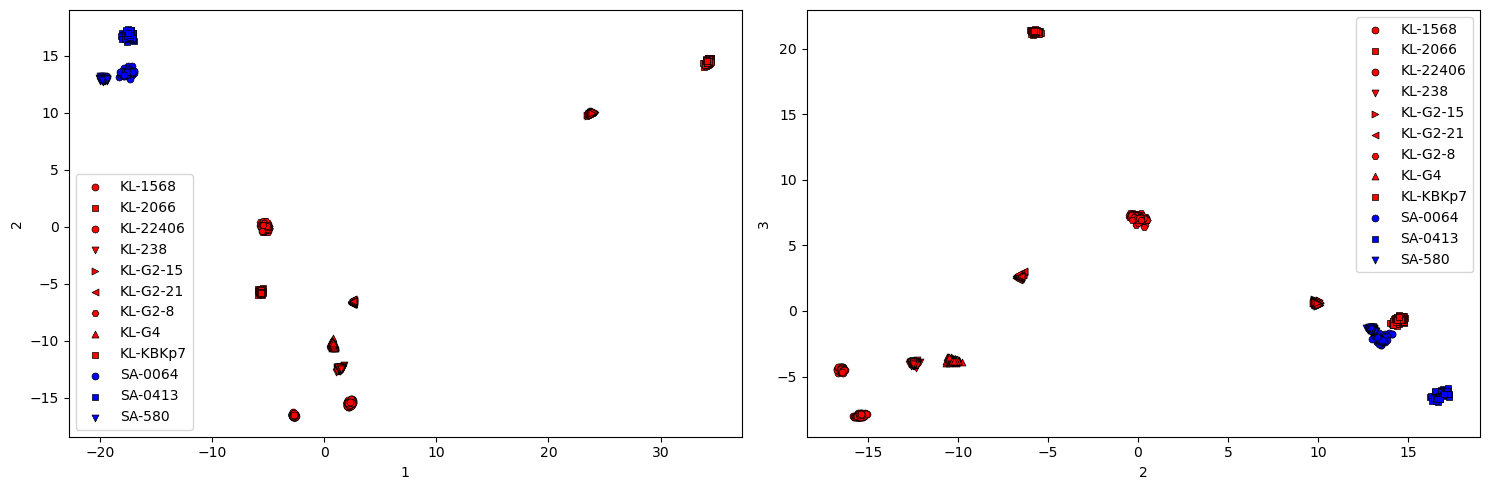

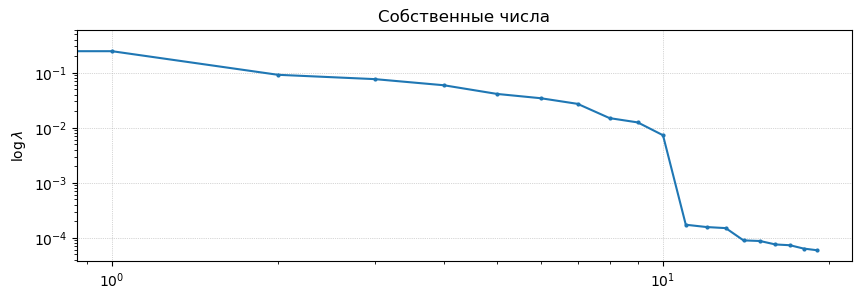

In [25]:
Ys = [dd2.spectra[key].y for key in dd2.spectra]
names = [key for key in dd2.spectra.keys()]
# print(names)
plot_pca(xs, Ys, names, 
         colors=9*["r"] + 3*["b"], 
         markers=["o", "s", "o", "v", ">", "<", "H", "^", "s",    "o", "s", "v"],
         m=20, mm=2, kind="l2/l2", plot_eigenval=1)

In [11]:
# dd.crop(400)

In [12]:
# preprocess_step1(dd)

In [22]:
dd2.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', index=3, layout=Layout(width='75%'), options=('KL-1…

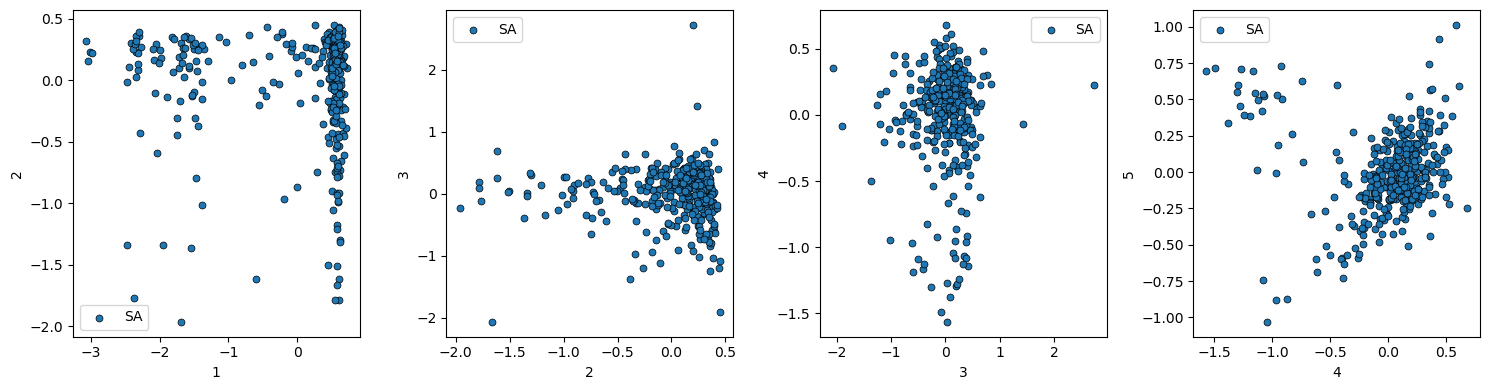

In [14]:
plot_pca(xs, [Ys_SA], ["SA"], m=10)

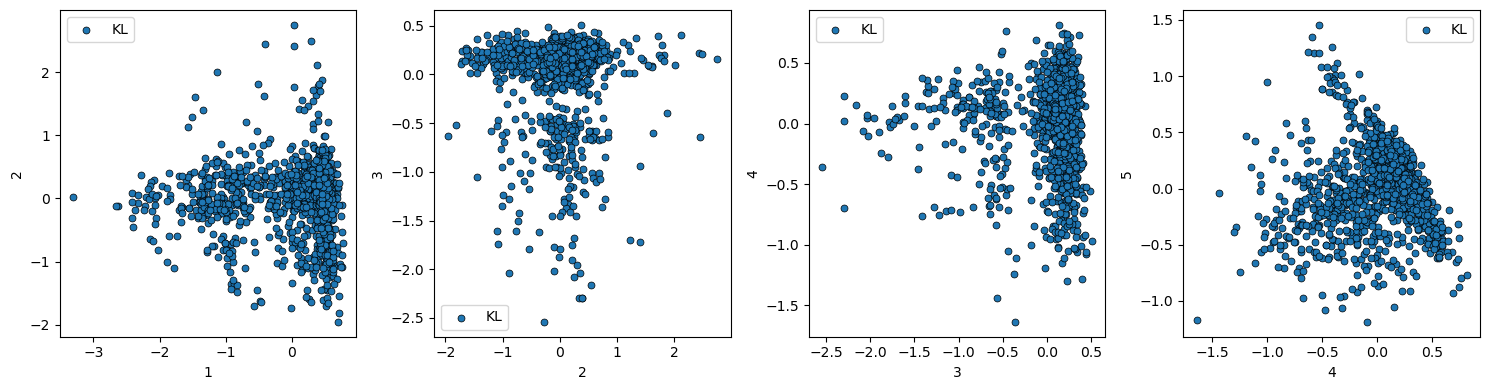

In [15]:
plot_pca(xs, [Ys_KL], ["KL"], m=10)

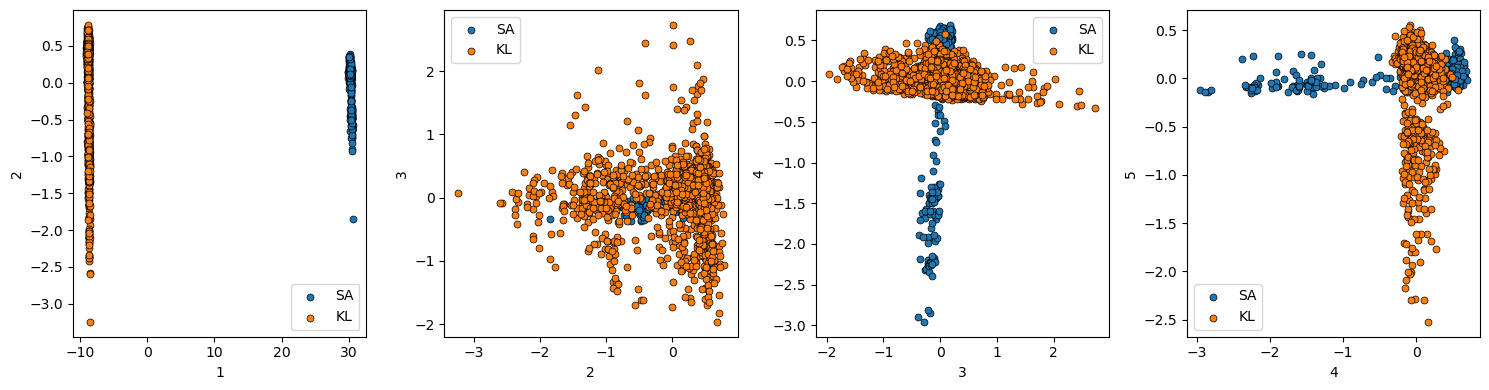

In [16]:
c, As = plot_pca(xs, [Ys_SA, Ys_KL], ["SA", "KL"], m=10, return_result=True)

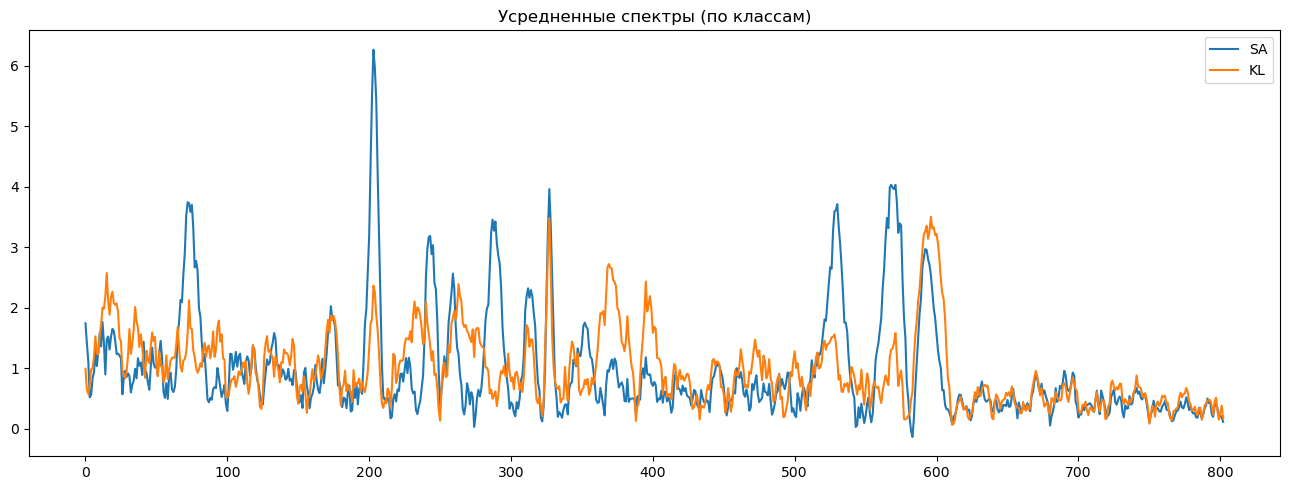

In [21]:
plt.figure(figsize=(13,5))
plt.title("Усредненные спектры (по классам)")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.plot(Ys_KL.mean(axis=0), label="KL")
plt.legend()
plt.tight_layout()
plt.show()

<Figure size 1300x300 with 0 Axes>

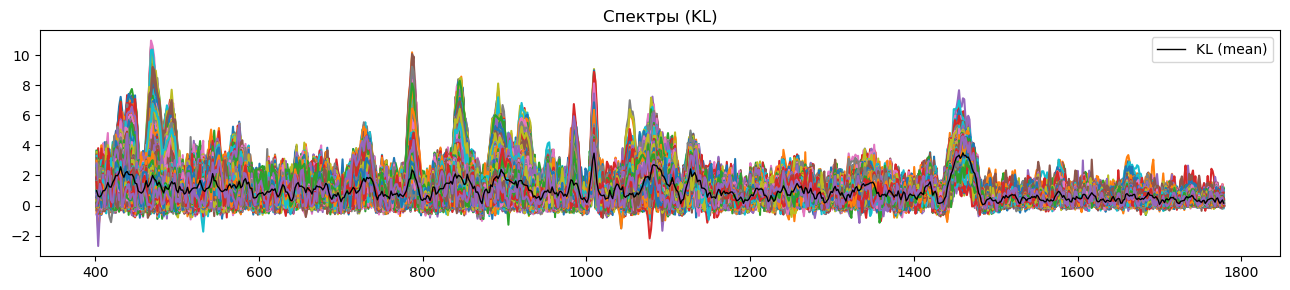

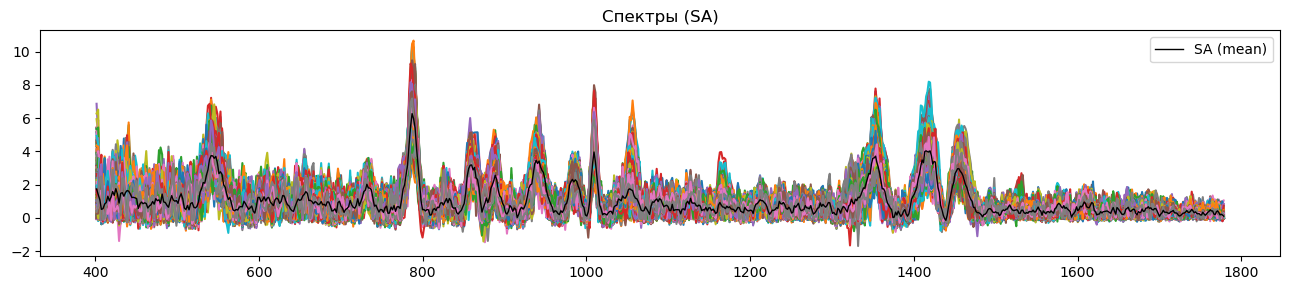

In [22]:
plt.figure(figsize=(13,3))
plt.figure(figsize=(13,3))
plt.title("Спектры (KL)")
for ys in Ys_KL:
    plt.plot(xs, ys)
plt.plot(xs, Ys_KL.mean(axis=0), lw=1.0, label="KL (mean)", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Спектры (SA)")
for ys in Ys_SA:
    plt.plot(xs, ys)
plt.plot(xs, Ys_SA.mean(axis=0), lw=1.0, label="SA (mean)", color='k')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
path = f"/home/intellimath/YD/repos/spectra/20"
dd20 = io.load_spectra(path, {
                            "вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["20"], 
                            "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })


In [21]:
msc = True
svd = False
preprocess_step1(dd20, msc=msc, svd=svd)

dd20_SA = dd20.union("SA", **{"вид_бактерий":"SA"})
dd20_SS = dd20.union("SS", **{"вид_бактерий":"SS"})
dd20_SH = dd20.union("SH", **{"вид_бактерий":"SH"})

preprocess_step2(dd20_SA, msc=msc, svd=svd)
preprocess_step2(dd20_SS, msc=msc, svd=svd)
preprocess_step2(dd20_SH, msc=msc, svd=svd)

dd20_flat = {"SA": dd20_SA, "SS": dd20_SS, "SH": dd20_SH,}

Ys20_SA = dd20_SA.y
Ys20_SS = dd20_SS.y
Ys20_SH = dd20_SH.y
Ys20 = np.concatenate([Ys20_SA, Ys20_SS, Ys20_SH], axis=0)

xs = dd20.same_x()
print(len(xs), len(Ys20_SA), len(Ys20_SS), len(Ys20_SH))


Step 1
Step 2
SA
Step 2
SS
Step 2
SH
803 144 137 153


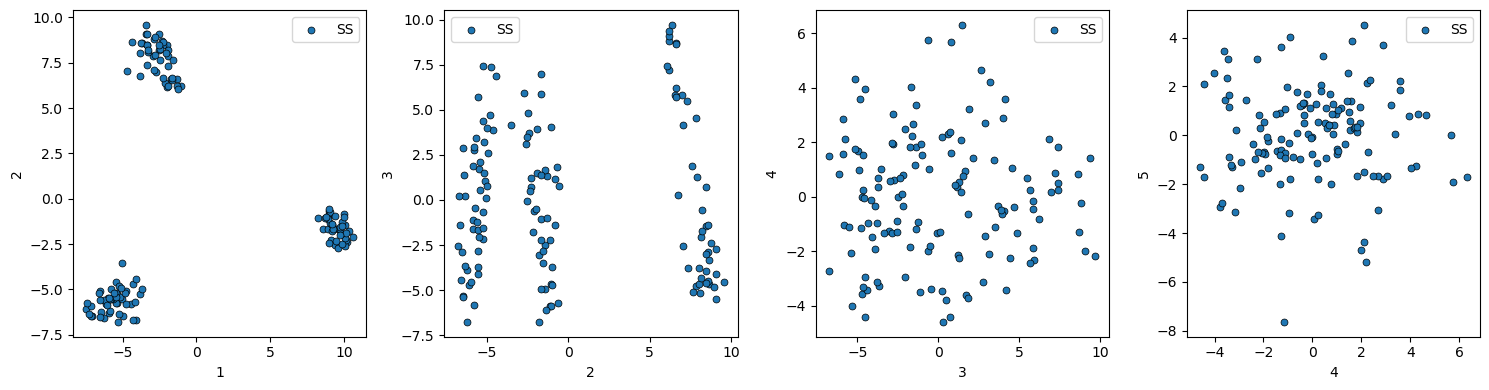

In [22]:
plot_pca(xs, [Ys20_SS], ["SS"], m=30)

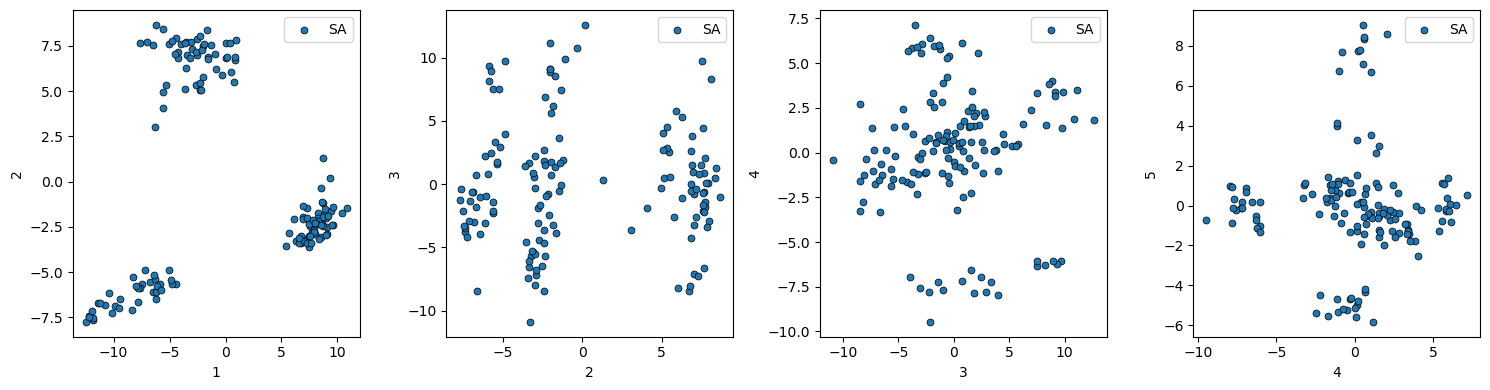

In [23]:
plot_pca(xs, [Ys20_SA], ["SA"], m=30)

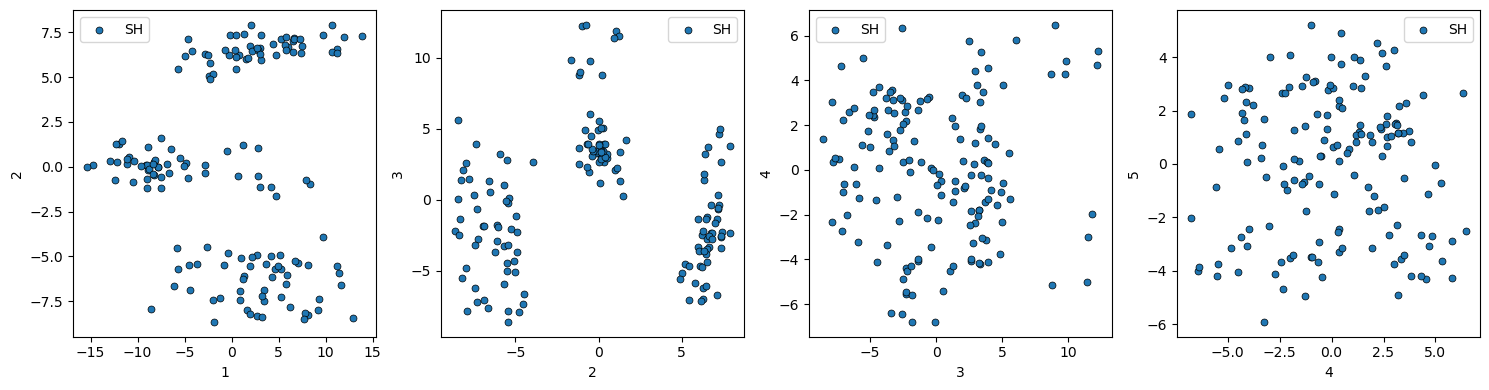

In [24]:
plot_pca(xs, [Ys20_SH], ["SH"], m=30)

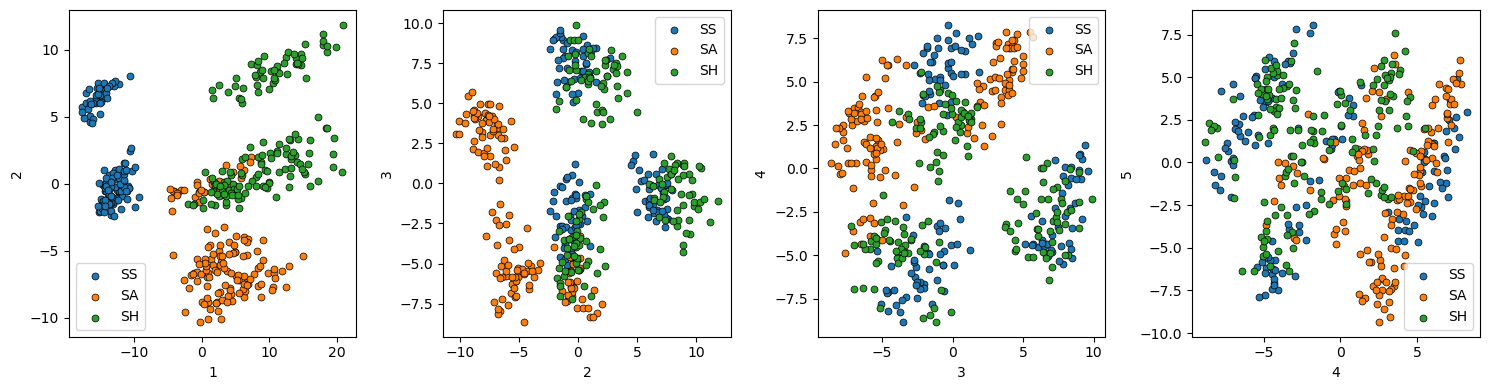

In [25]:
c20, As20 = plot_pca(xs, [Ys20_SS, Ys20_SA, Ys20_SH], ["SS", "SA", "SH"], m=30, return_result=True)

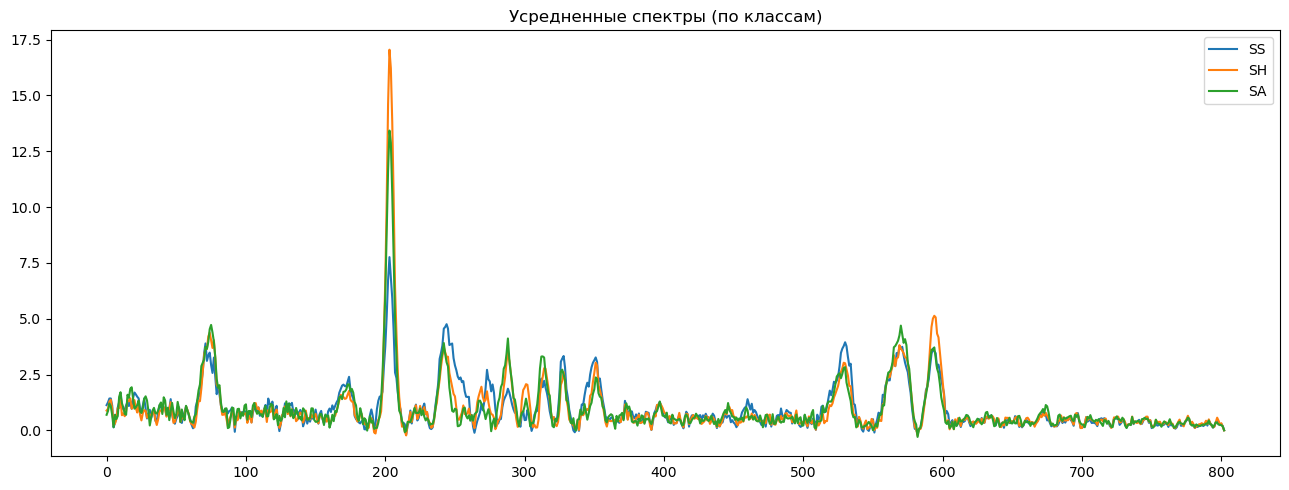

In [26]:
plt.figure(figsize=(13,5))
plt.title("Усредненные спектры (по классам)")
plt.plot(Ys20_SS.mean(axis=0), label="SS")
plt.plot(Ys20_SH.mean(axis=0), label="SH")
plt.plot(Ys20_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

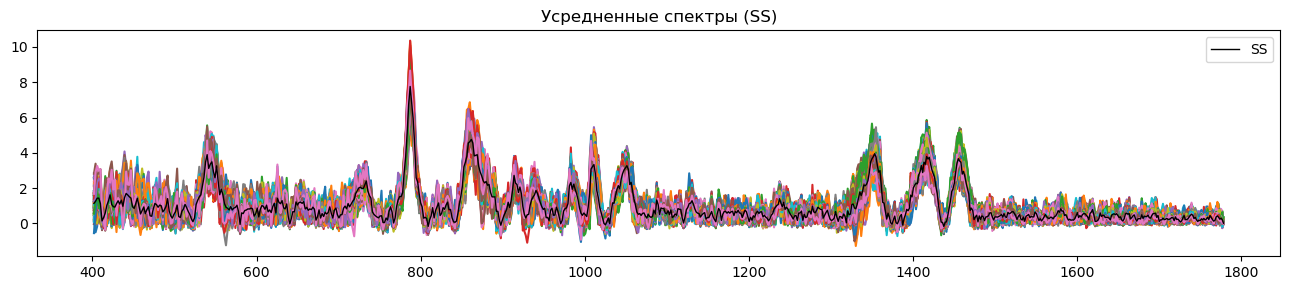

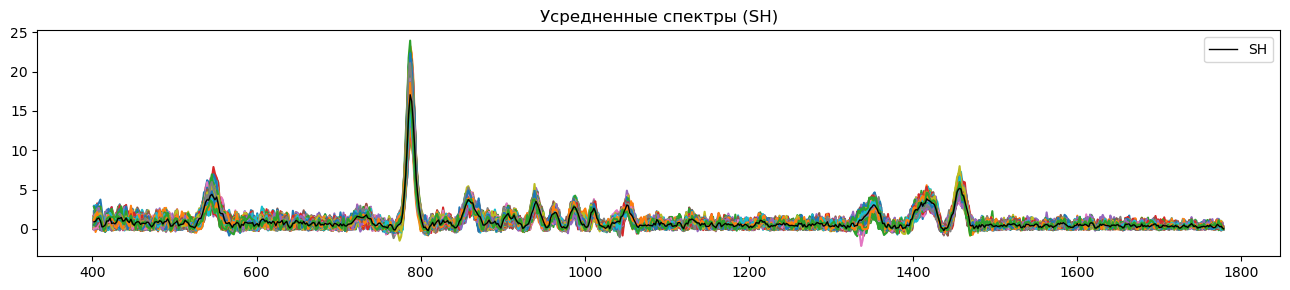

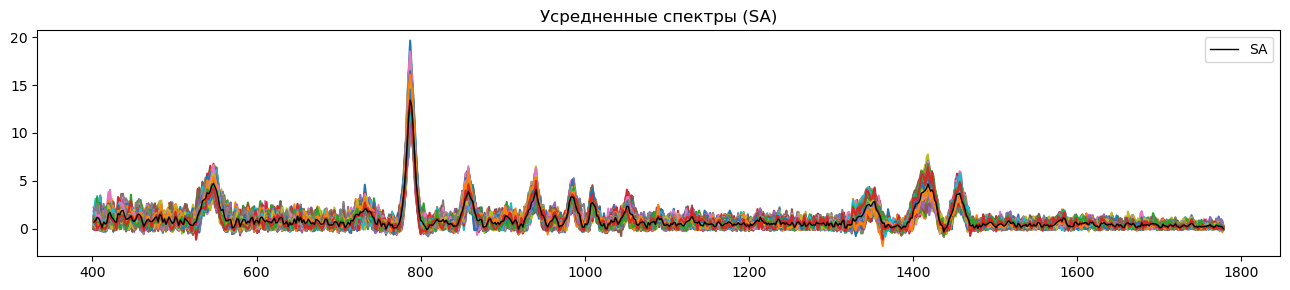

In [27]:
plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SS)")
for ys in Ys20_SS:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SS.mean(axis=0), lw=1.0, label="SS", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SH)")
for ys in Ys20_SH:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SH.mean(axis=0), lw=1.0, label="SH", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SA)")
for ys in Ys20_SA:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SA.mean(axis=0), lw=1.0, label="SA", color='k')
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
path = f"/home/intellimath/YD/repos/spectra/20"
dd20 = io.load_spectra(path, {
                            "вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["20"], 
                            "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })


In [29]:
msc = False
svd = True
preprocess_step1(dd20, msc=msc, svd=svd)

dd20_SA = dd20.union("SA", **{"вид_бактерий":"SA"})
dd20_SS = dd20.union("SS", **{"вид_бактерий":"SS"})
dd20_SH = dd20.union("SH", **{"вид_бактерий":"SH"})

preprocess_step2(dd20_SA, msc=msc, svd=svd)
preprocess_step2(dd20_SS, msc=msc, svd=svd)
preprocess_step2(dd20_SH, msc=msc, svd=svd)

dd20_flat = {"SA": dd20_SA, "SS": dd20_SS, "SH": dd20_SH,}

Ys20_SA = dd20_SA.y
Ys20_SS = dd20_SS.y
Ys20_SH = dd20_SH.y
Ys20 = np.concatenate([Ys20_SA, Ys20_SS, Ys20_SH], axis=0)

xs = dd20.same_x()
print(len(xs), len(Ys20_SA), len(Ys20_SS), len(Ys20_SH))


Step 1
Step 2
SA
Step 2
SS
Step 2
SH
803 141 124 161


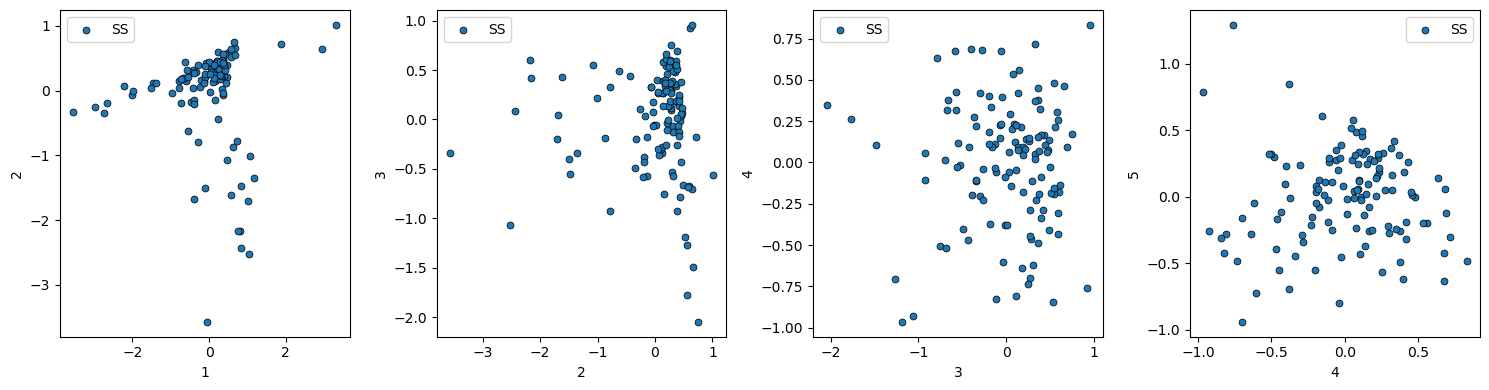

In [31]:
plot_pca(xs, [Ys20_SS], ["SS"], m=30)

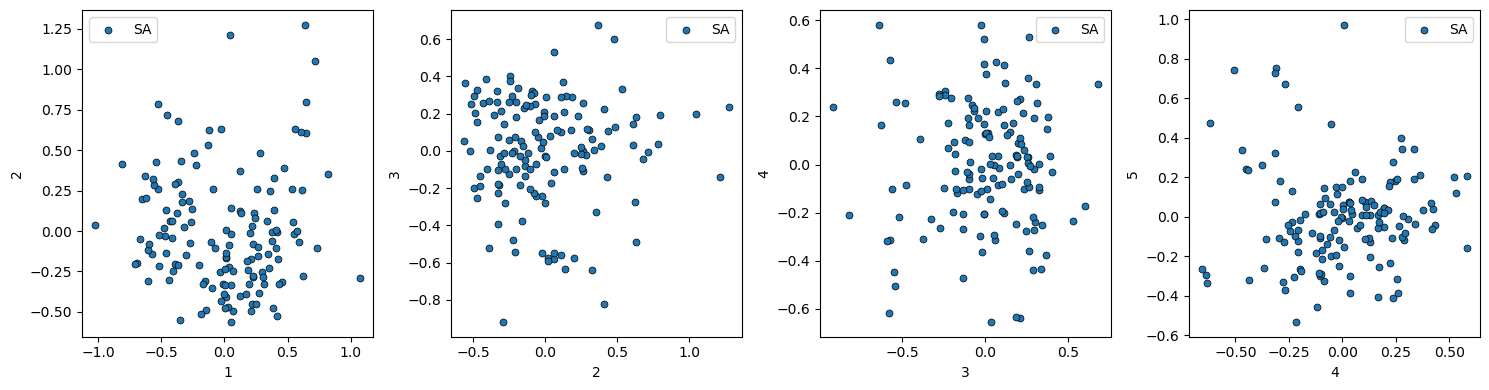

In [32]:
plot_pca(xs, [Ys20_SA], ["SA"], m=30)

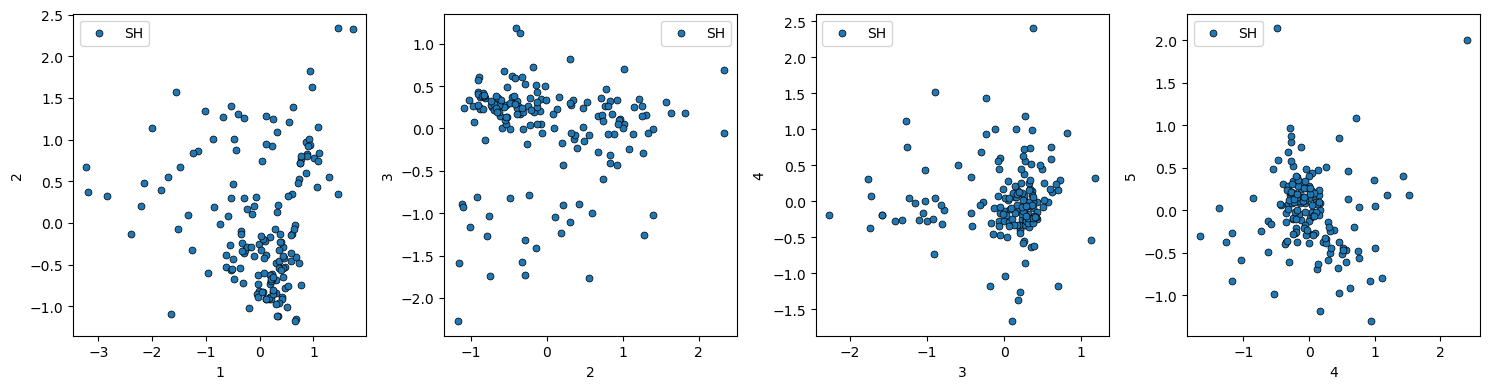

In [33]:
plot_pca(xs, [Ys20_SH], ["SH"], m=30)

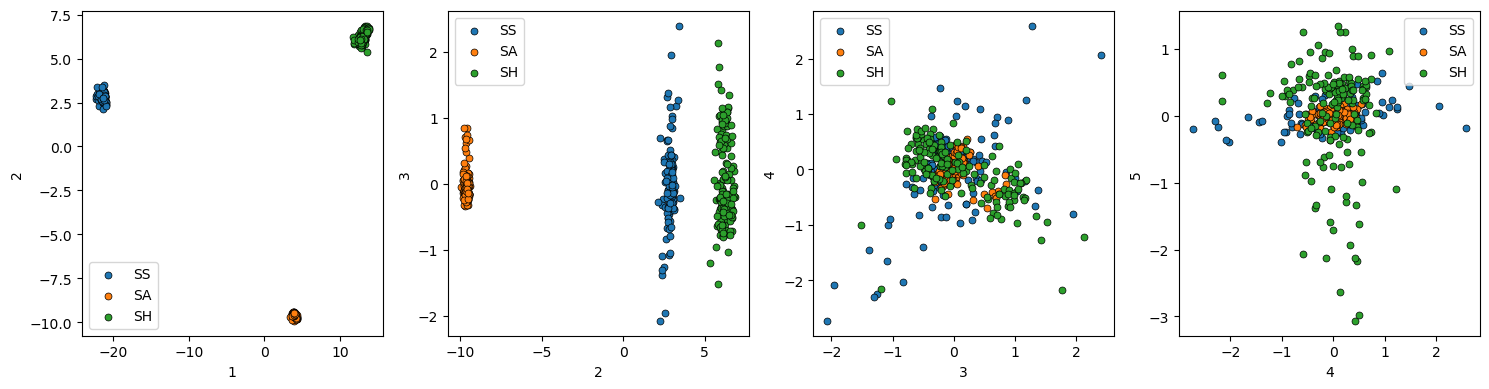

In [34]:
c20, As20 = plot_pca(xs, [Ys20_SS, Ys20_SA, Ys20_SH], ["SS", "SA", "SH"], m=30, return_result=True)

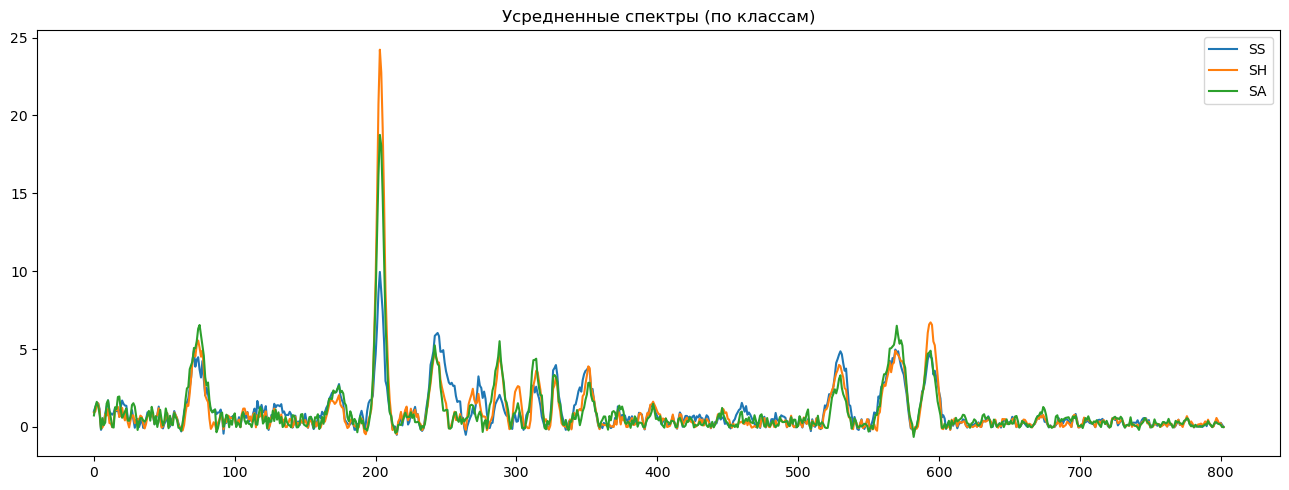

In [30]:
plt.figure(figsize=(13,5))
plt.title("Усредненные спектры (по классам)")
plt.plot(Ys20_SS.mean(axis=0), label="SS")
plt.plot(Ys20_SH.mean(axis=0), label="SH")
plt.plot(Ys20_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

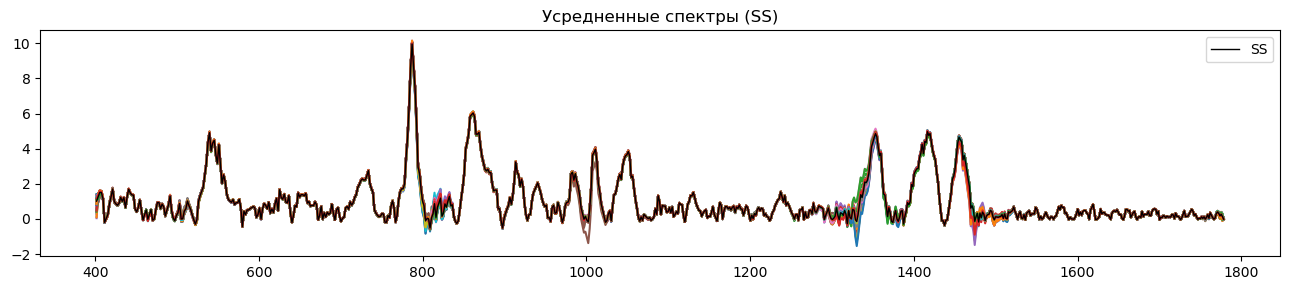

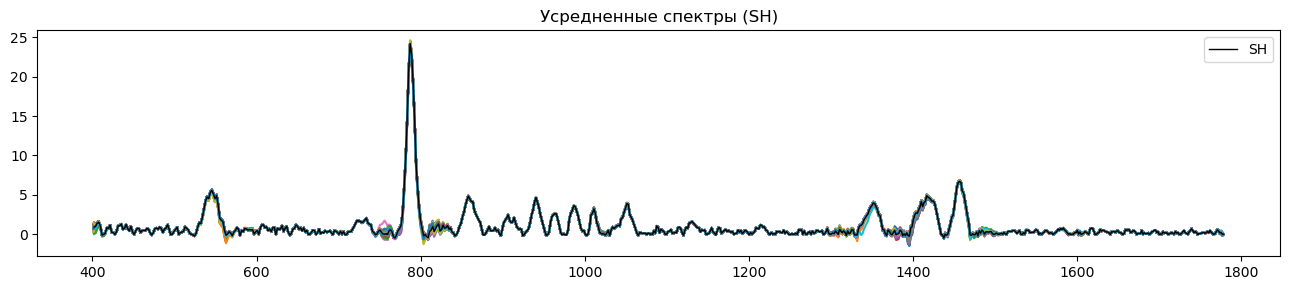

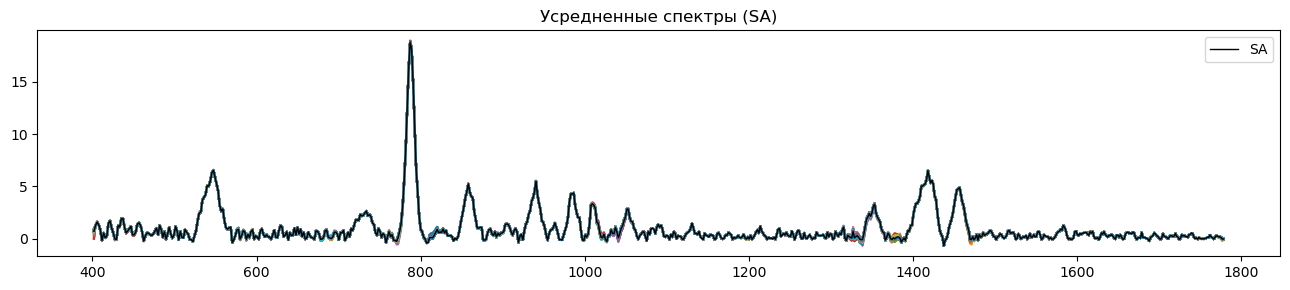

In [35]:
plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SS)")
for ys in Ys20_SS:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SS.mean(axis=0), lw=1.0, label="SS", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SH)")
for ys in Ys20_SH:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SH.mean(axis=0), lw=1.0, label="SH", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SA)")
for ys in Ys20_SA:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SA.mean(axis=0), lw=1.0, label="SA", color='k')
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
path = f"/home/intellimath/YD/repos/spectra/20"
dd20 = io.load_spectra(path, {
                            "вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["20"], 
                            "лизис":["термический"],
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],
                           })


In [37]:
msc = True
svd = True
preprocess_step1(dd20, msc=msc, svd=svd)

dd20_SA = dd20.union("SA", **{"вид_бактерий":"SA"})
dd20_SS = dd20.union("SS", **{"вид_бактерий":"SS"})
dd20_SH = dd20.union("SH", **{"вид_бактерий":"SH"})

preprocess_step2(dd20_SA, msc=msc, svd=svd)
preprocess_step2(dd20_SS, msc=msc, svd=svd)
preprocess_step2(dd20_SH, msc=msc, svd=svd)

dd20_flat = {"SA": dd20_SA, "SS": dd20_SS, "SH": dd20_SH,}

Ys20_SA = dd20_SA.y
Ys20_SS = dd20_SS.y
Ys20_SH = dd20_SH.y
Ys20 = np.concatenate([Ys20_SA, Ys20_SS, Ys20_SH], axis=0)

xs = dd20.same_x()
print(len(xs), len(Ys20_SA), len(Ys20_SS), len(Ys20_SH))


Step 1
Step 2
SA
Step 2
SS
Step 2
SH
803 144 133 134


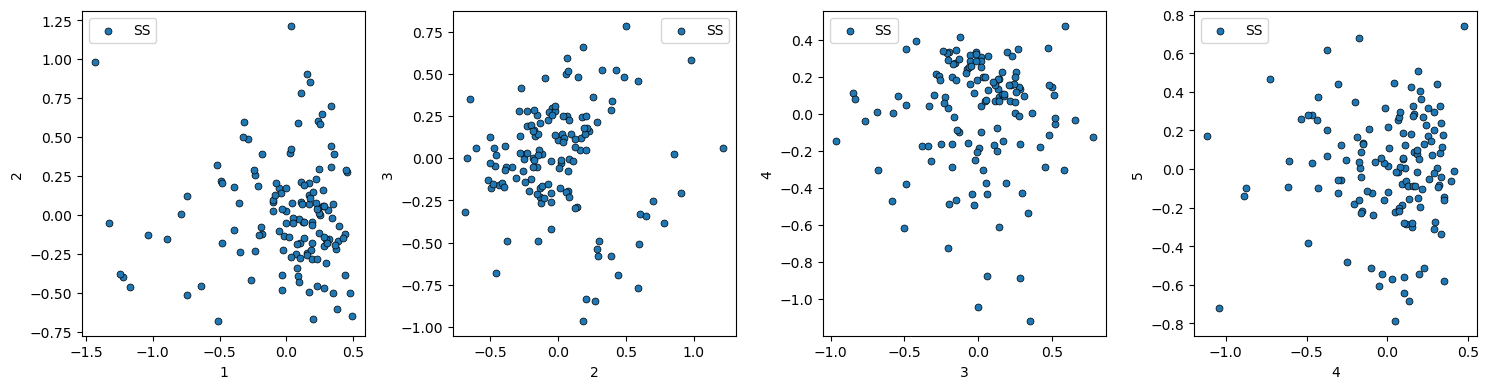

In [39]:
plot_pca(xs, [Ys20_SS], ["SS"], m=30)

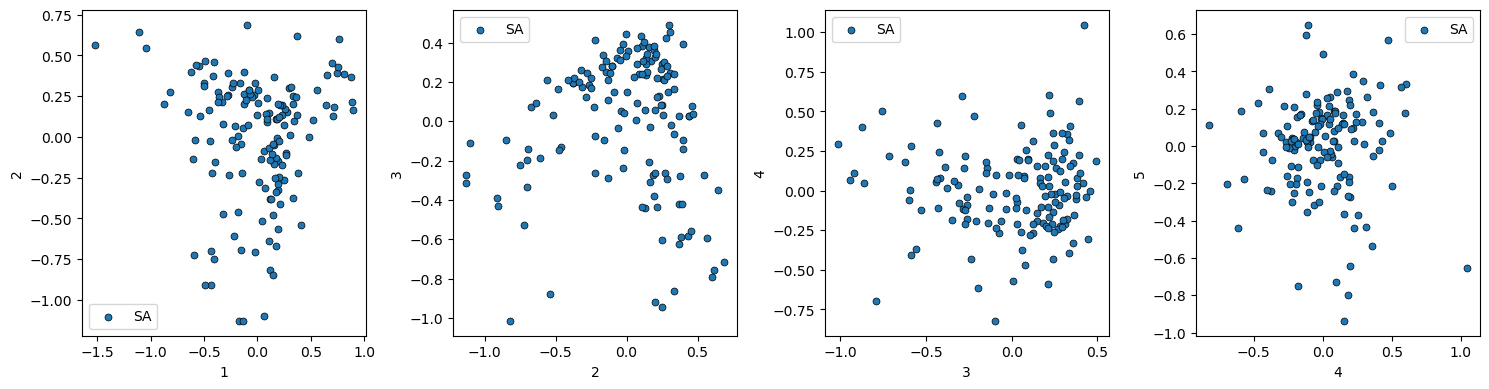

In [40]:
plot_pca(xs, [Ys20_SA], ["SA"], m=30)

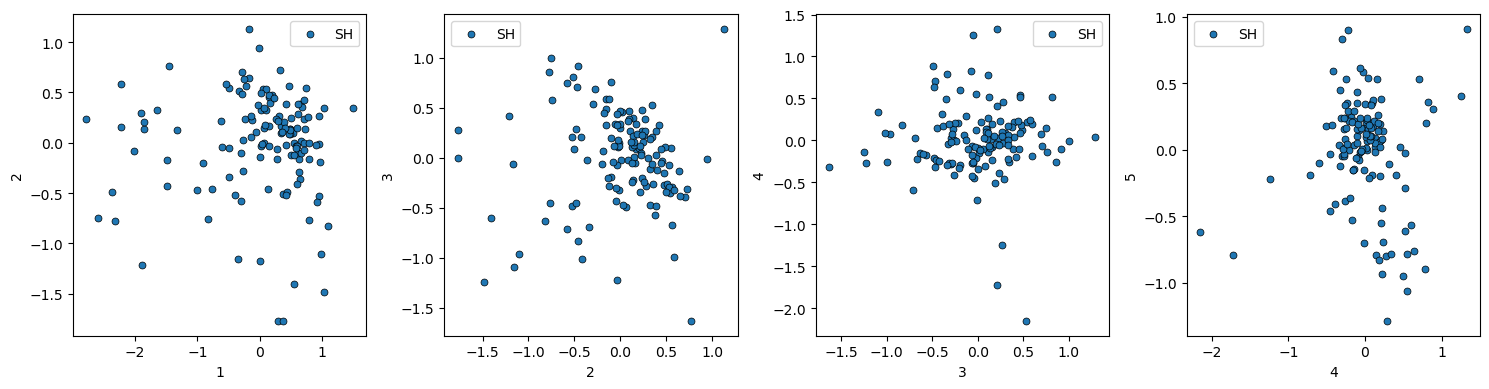

In [41]:
plot_pca(xs, [Ys20_SH], ["SH"], m=30)

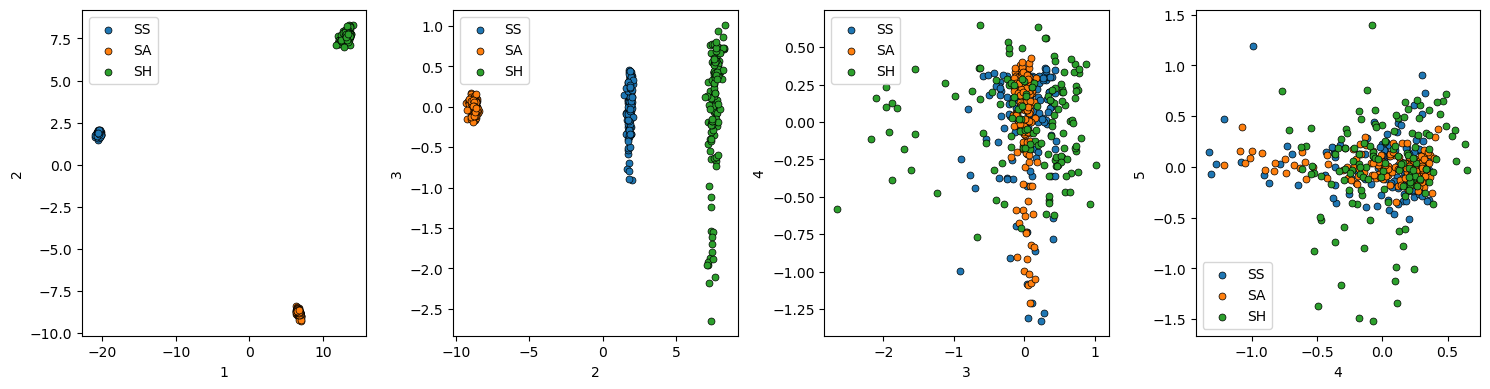

In [42]:
c20, As20 = plot_pca(xs, [Ys20_SS, Ys20_SA, Ys20_SH], ["SS", "SA", "SH"], m=30, return_result=True)

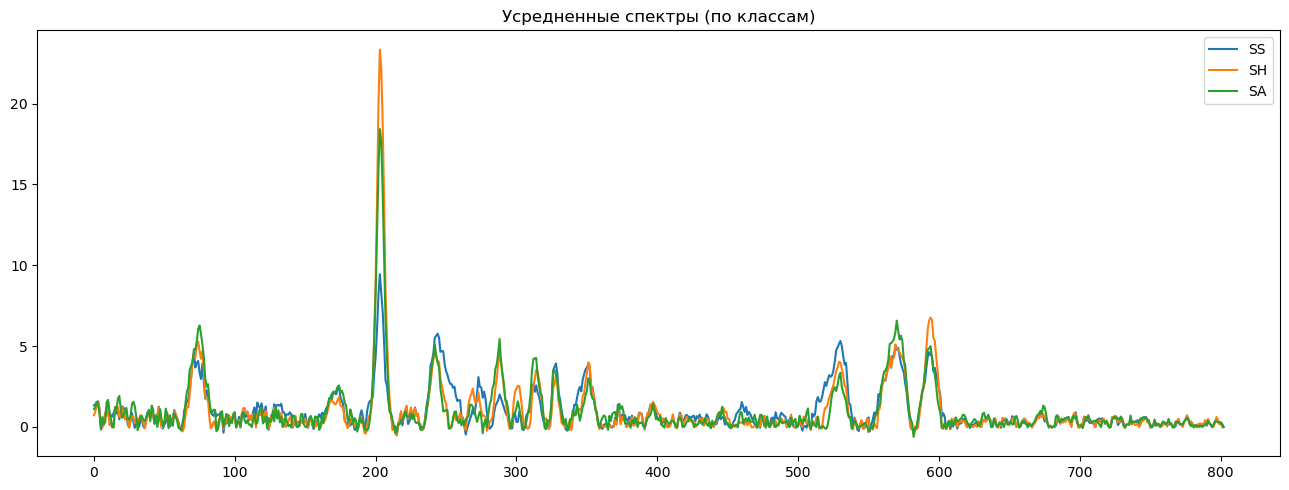

In [43]:
plt.figure(figsize=(13,5))
plt.title("Усредненные спектры (по классам)")
plt.plot(Ys20_SS.mean(axis=0), label="SS")
plt.plot(Ys20_SH.mean(axis=0), label="SH")
plt.plot(Ys20_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

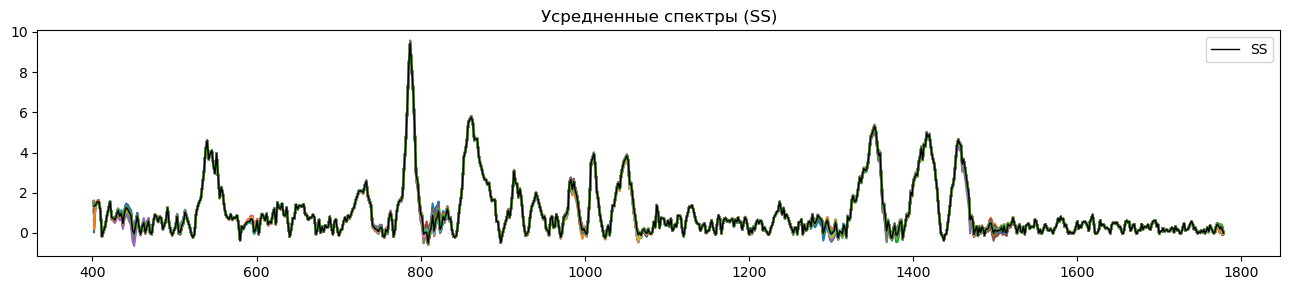

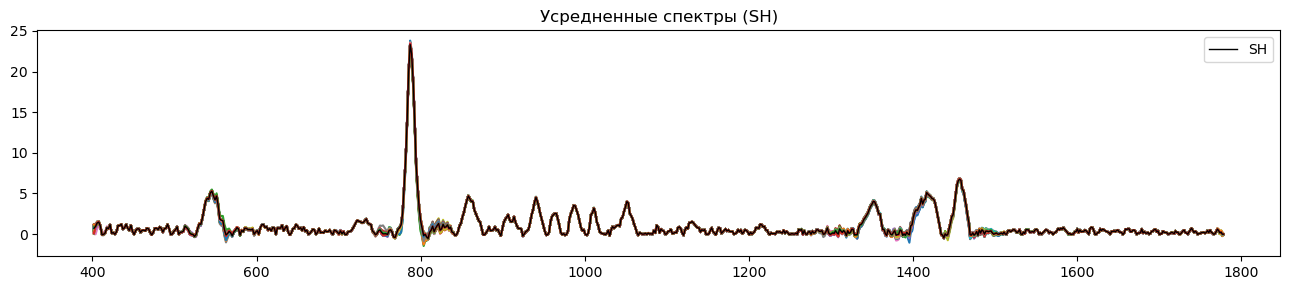

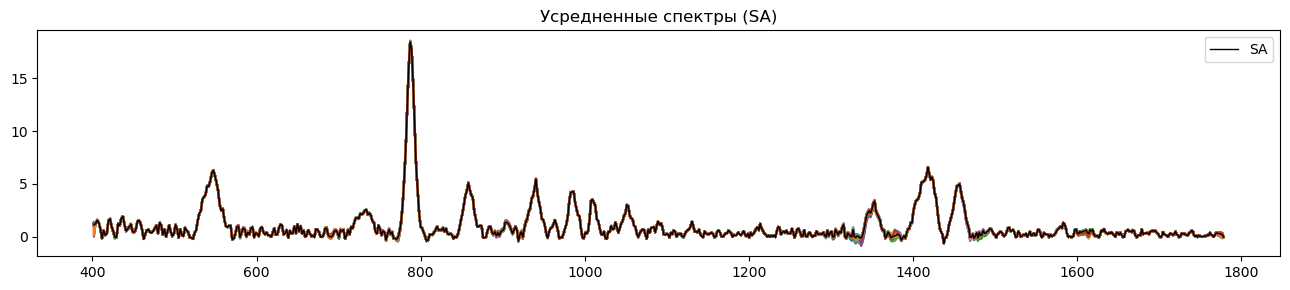

In [44]:
plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SS)")
for ys in Ys20_SS:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SS.mean(axis=0), lw=1.0, label="SS", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SH)")
for ys in Ys20_SH:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SH.mean(axis=0), lw=1.0, label="SH", color='k')
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(13,3))
plt.title("Усредненные спектры (SA)")
for ys in Ys20_SA:
    plt.plot(xs, ys)
plt.plot(xs, Ys20_SA.mean(axis=0), lw=1.0, label="SA", color='k')
plt.legend()
plt.tight_layout()
plt.show()

# Спектры 21-й серии

In [45]:
path = f"/home/intellimath/YD/repos/spectra/21_SU"
dd21 = io.load_spectra(path, { #"вид_бактерий":["A", "B", "C", "D"], 
                            # "номер_цикла":["1"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],                            
                           }, verbose=False)

In [46]:
import pandas as pd
df = pd.read_csv("spectra_21_tab1.csv", sep="\t")
cls_col = df["cls"]
cls_name_col = cls_col.apply(lambda x: x.split("/")[0][:2])
cls_nn_col = cls_col.apply(lambda x: x.split("/")[1])
df.__delitem__("cls")
df["cls_name"] = cls_name_col
df["cls_nn"] = cls_nn_col
id1_array = df["id1"].values
id2_array = df["id2"].values
id_to_cls = {int(id):name.upper() for id,name in zip(id1_array, cls_name_col.values)}
id_to_cls

{75: 'SA',
 52: 'SA',
 72: 'SA',
 22: 'SA',
 2: 'SA',
 3: 'SA',
 4: 'SA',
 11: 'SA',
 19: 'SA',
 64: 'SA',
 37: 'SA',
 38: 'SA',
 56: 'SH',
 17: 'SH',
 43: 'SH',
 44: 'SH',
 45: 'SH',
 5: 'SH',
 6: 'SH',
 7: 'SH',
 20: 'SH',
 12: 'SH',
 53: 'SH',
 23: 'SH',
 57: 'SS',
 58: 'SS',
 79: 'SS',
 80: 'SS',
 18: 'SS',
 63: 'SS',
 24: 'SS',
 13: 'SS',
 14: 'SS',
 15: 'SS',
 16: 'SS',
 65: 'SS',
 66: 'SS',
 21: 'SS',
 47: 'SS',
 48: 'SS'}

In [47]:
dd1 = spectra.SpectraCollection()
for key in dd21.spectra.keys():
    keys = key.split("_")
    id0 = keys[0]
    id = int(id0[2:])
    keys[1] = id0
    keys[0] = id_to_cls[id].upper()
    new_key = "_".join(keys)
    sp = dd21.spectra[key]
    sp.attrs["key"] = new_key
    sp.attrs["вид_бактерий"] = keys[0]
    dd1[new_key] = sp
dd21 = dd1
del dd1

In [48]:
# dd21.crop(200)

In [49]:
# dd21.plot_spectra()

In [45]:
# dd21.select_baselines(tau2=1.0e1, tau1=-0.0001,
#                       func=funcs.RStep(0.0, 0.0),
#                       # func2=funcs.SoftAbs_Sqrt(1.0).derivative_div_array,
#                       func2_e=inventory.relative_abs_max,
#                       # verbose=False,
#                       d=2,
# )

In [50]:
msc = True
svd = True
preprocess_step1(dd21, msc=msc, svd=svd)

dd21_SA = dd21.union("SA", **{"вид_бактерий":"SA"})
dd21_SS = dd21.union("SS", **{"вид_бактерий":"SS"})
dd21_SH = dd21.union("SH", **{"вид_бактерий":"SH"})

preprocess_step2(dd21_SA, msc=msc, svd=svd)
preprocess_step2(dd21_SS, msc=msc, svd=svd)
preprocess_step2(dd21_SH, msc=msc, svd=svd)

# dd21_SA.multiplicative_scatter_correction()
# dd21_SS.multiplicative_scatter_correction()
# dd21_SH.multiplicative_scatter_correction()

dd21_flat = {"SA": dd21_SA, "SS": dd21_SS, "SH": dd21_SH,}

Ys21_SA = dd21_SA.y
Ys21_SS = dd21_SS.y
Ys21_SH = dd21_SH.y
Ys21 = np.concatenate([Ys21_SA, Ys21_SS, Ys21_SH], axis=0)

xs = dd21.same_x()
print(len(xs), len(Ys21_SA), len(Ys21_SS), len(Ys21_SH))


Step 1
Step 2
SA
Step 2
SS
Step 2
SH
803 195 244 181


In [47]:
# dd21.plot_spectra()

In [48]:
# dd21.select_baselines(tau2=1.0e3, tau1=-0.0001,
#                      func=funcs.RStep(0.01, 0.0001), 
#                      func2_e=inventory.relative_abs_max,                     
#                     )

In [49]:
# dd20.plot_spectra()

In [50]:
# dd21.plot_spectra()

In [51]:
# dd21_SA.plot_spectra()

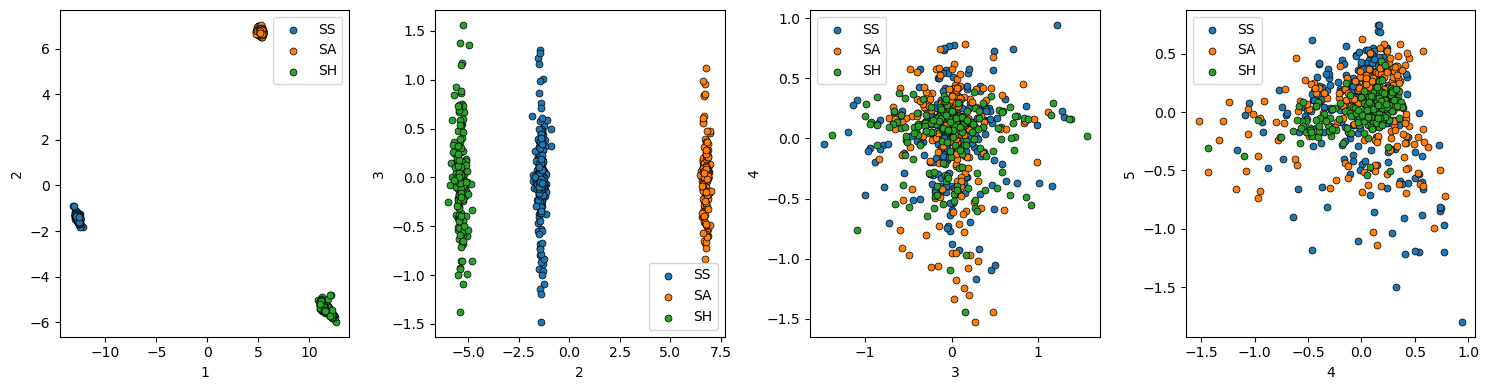

In [51]:
c21, As21 = plot_pca(xs, [Ys21_SS, Ys21_SA, Ys21_SH], ["SS", "SA", "SH"], return_result=True)

In [ ]:
# plot_pca_l1_l2(xs, Ys21, Ys21_SS, Ys21_SA, Ys21_SH, m=15)

In [ ]:
# plot_pca_l2_lq(xs, Ys21, Ys21_SS, Ys21_SA, Ys21_SH, p=1.5, m=15)

In [ ]:
# wma = averaging_function("WMZ", kwds={"alpha":2.0})
# plot_robust_pca(Ys21, Ys21_SS, Ys21_SA, Ys21_SH, wma)

In [ ]:
# def rescale_by(X, Y):
#     mu_y = np.median(Y, axis=0)
#     sigma_y = np.median(abs(Y - mu_y))
#     mu_x = np.median(X, axis=0)
#     sigma_x = np.median(abs(X - mu_x))
#     return (X - mu_x) / sigma_x * sigma_y + mu_y
    

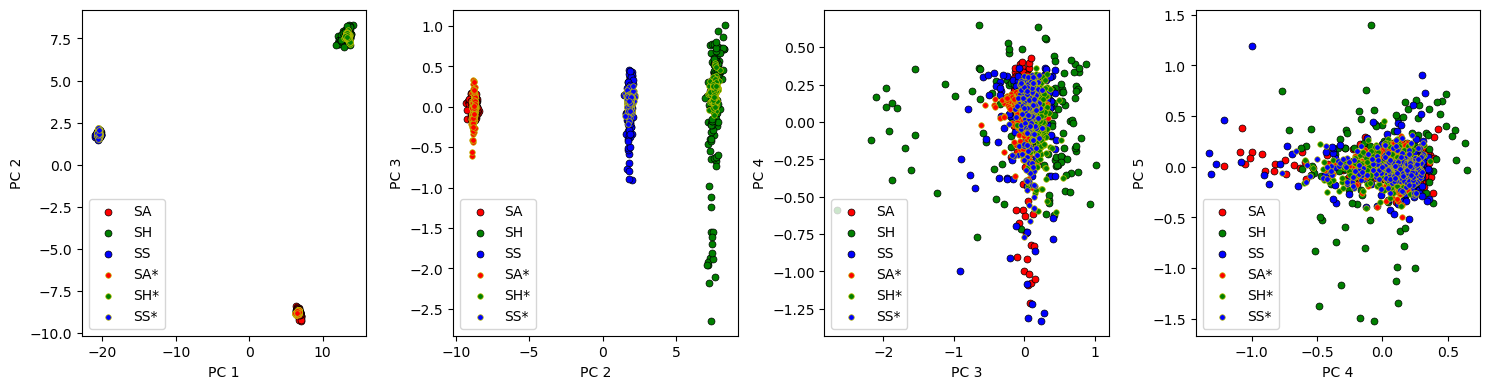

In [52]:
# Ys = np.vstack((Ys20,Ys21))
c, As, Ls = pca.find_loc_and_pc(Ys20, 5)

Ys21_SA_s = rescale_by(Ys21_SA, Ys20_SA)
Ys21_SS_s = rescale_by(Ys21_SS, Ys20_SS)
Ys21_SH_s = rescale_by(Ys21_SH, Ys20_SH)

# U = (Ys - c) @ As.T
U20_SS = (Ys20_SS - c) @ As.T
U20_SA = (Ys20_SA - c) @ As.T
U20_SH = (Ys20_SH - c) @ As.T
U21_SS = (Ys21_SS_s - c) @ As.T
U21_SA = (Ys21_SA_s - c) @ As.T
U21_SH = (Ys21_SH_s - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U20_SA[:,i], U20_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U20_SH[:,i], U20_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U20_SS[:,i], U20_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.scatter(U21_SA[:,i], U21_SA[:,i+1], s=16, c='r', edgecolors='y', linewidth=0.5, label="SA*")
    plt.scatter(U21_SH[:,i], U21_SH[:,i+1], s=16, c='g', edgecolors='y', linewidth=0.5, label="SH*")
    plt.scatter(U21_SS[:,i], U21_SS[:,i+1], s=16, c='b', edgecolors='y', linewidth=0.5, label="SS*")
    plt.xlabel(f"PC {str(i+1)}")
    plt.ylabel(f"PC {str(i+2)}")
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()


## Серия 22

In [55]:
path = f"/home/intellimath/YD/repos/spectra/22_SU"
dd22 = io.load_spectra(path, { #"вид_бактерий":["A", "B", "C", "D"], 
                            # "номер_цикла":["1"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            "отсечки_по_молекулярной_массе": ["super"],                            
                           }, verbose=False)

In [56]:
import pandas as pd
df = pd.read_csv("spectra_22_tab1.csv", sep=",")
cls_col = df["cls"]
cls_name_col = cls_col.apply(lambda x: x.split(" ")[0][:2])
cls_nn_col = cls_col.apply(lambda x: x.split(" ")[1])
df.__delitem__("cls")
df["cls_name"] = cls_name_col
df["cls_nn"] = cls_nn_col
id1_array = df["id1"].values
id2_array = df["id2"].values
id_to_cls = {id:name.upper() for id,name in zip(id1_array, cls_name_col.values)}
id_to_cls

{'SU1': 'SS',
 'SU2': 'SA',
 'SU3': 'SS',
 'SU4': 'SH',
 'SU5': 'SA',
 'SU6': 'SA',
 'SU7': 'SS',
 'SU8': 'SH',
 'SU9': 'SA',
 'SU10': 'SH',
 'SU11': 'SH',
 'SU12': 'SS',
 'SU13': 'SS',
 'SU14': 'SA',
 'SU15': 'SH',
 'SU16': 'SS',
 'SU17': 'SH',
 'SU18': 'SS',
 'SU19': 'SA',
 'SU20': 'SS'}

In [57]:
dd1 = spectra.SpectraCollection()
for key in dd22.spectra.keys():
    key0 = key.split("_")[0]
    name = id_to_cls[key0]
    sp = dd22.spectra[key]
    new_key = name + "_" + key0 
    sp.attrs["key"] = new_key
    sp.attrs["вид_бактерий"] = name
    dd1[new_key] = sp
dd22 = dd1
del dd1

In [58]:
# dd22.crop(200)

In [59]:
# dd22.denoise_svd()

In [60]:
# dd22.plot_spectra()

In [61]:
# dd22.plot_hist(bins=100)

In [62]:
# dd22.select_baselines(tau2=1.0e4, tau1=-1.0e-3,
#                       func=funcs.RStep(0.0, 0.00),
#                       func2_e=inventory.relative_abs_max,
#                      )

In [63]:
msc = True
svd = True
preprocess_step1(dd22, msc=msc, svd=svd)

dd22_SA = dd22.union("SA", **{"вид_бактерий":"SA"})
dd22_SS = dd22.union("SS", **{"вид_бактерий":"SS"})
dd22_SH = dd22.union("SH", **{"вид_бактерий":"SH"})

preprocess_step2(dd22_SA, msc=msc, svd=svd)
preprocess_step2(dd22_SS, msc=msc, svd=svd)
preprocess_step2(dd22_SH, msc=msc, svd=svd)

# dd21_SA.multiplicative_scatter_correction()
# dd21_SS.multiplicative_scatter_correction()
# dd21_SH.multiplicative_scatter_correction()

dd22_flat = {"SA": dd22_SA, "SS": dd22_SS, "SH": dd22_SH,}

Ys22_SA = dd22_SA.y
Ys22_SS = dd22_SS.y
Ys22_SH = dd22_SH.y
Ys22 = np.concatenate([Ys22_SA, Ys22_SS, Ys22_SH], axis=0)

xs = dd22.same_x()
print(len(xs), len(Ys22_SA), len(Ys22_SS), len(Ys22_SH))


Step 1
Step 2
SA
Step 2
SS
Step 2
SH
803 77 124 97


In [64]:
# dd22.plot_spectra()

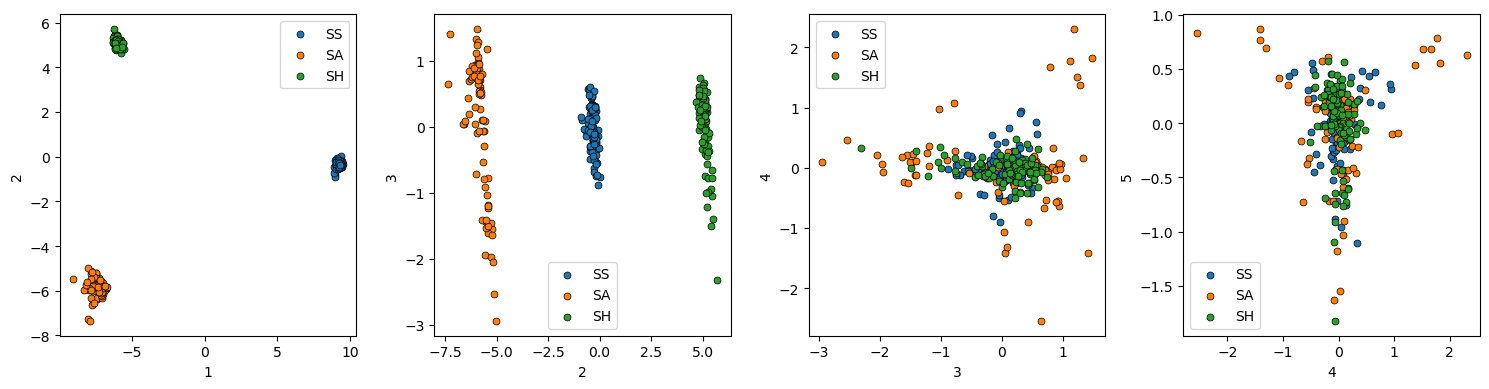

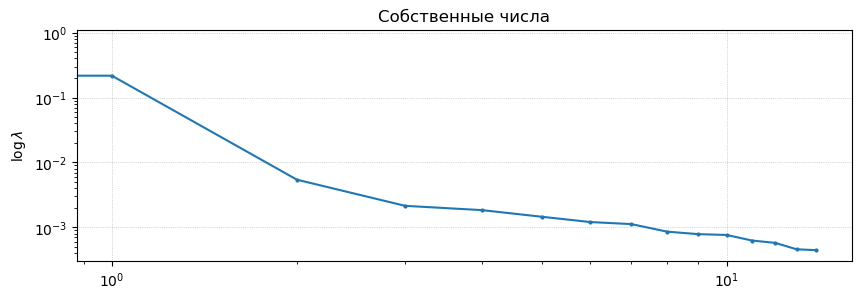

In [65]:
_ = plot_pca(xs, [Ys22_SS, Ys22_SA, Ys22_SH], ["SS", "SA", "SH"], m=15)

In [66]:
# wma = averaging_function("WMZ", kwds={"alpha":2.0})
# plot_robust_pca(Ys22_SS, Ys22_SA, Ys22_SH, wma)

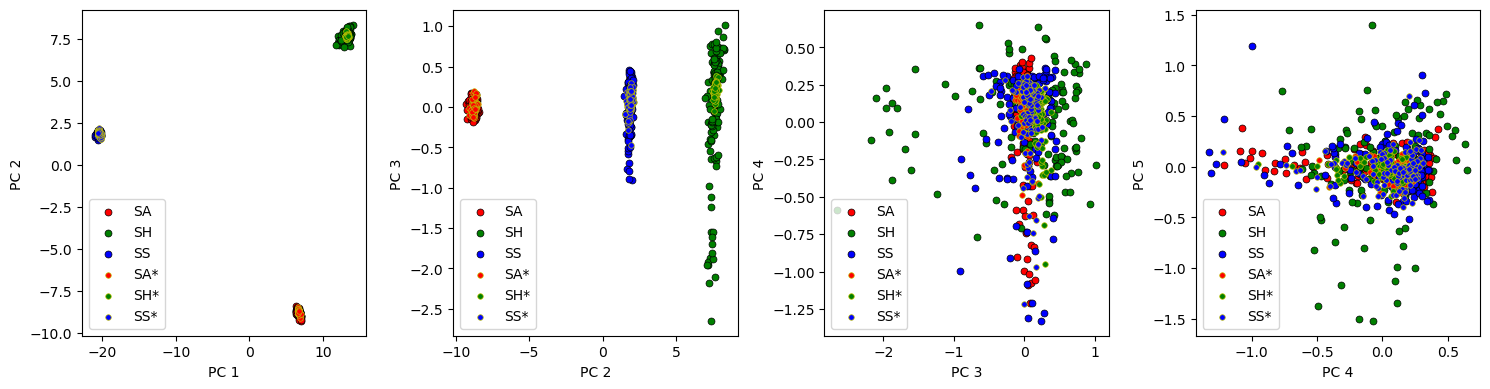

In [67]:
c, As, Ls = pca.find_loc_and_pc(Ys20, 5)

Ys22_SA_s = rescale_by(Ys22_SA, Ys20_SA)
Ys22_SS_s = rescale_by(Ys22_SS, Ys20_SS)
Ys22_SH_s = rescale_by(Ys22_SH, Ys20_SH)

# U = (Ys - c) @ As.T
U20_SS = (Ys20_SS - c) @ As.T
U20_SA = (Ys20_SA - c) @ As.T
U20_SH = (Ys20_SH - c) @ As.T
U22_SS = (Ys22_SS_s - c) @ As.T
U22_SA = (Ys22_SA_s - c) @ As.T
U22_SH = (Ys22_SH_s - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U20_SA[:,i], U20_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U20_SH[:,i], U20_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U20_SS[:,i], U20_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.scatter(U22_SA[:,i], U22_SA[:,i+1], s=16, c='r', edgecolors='y', linewidth=0.5, label="SA*")
    plt.scatter(U22_SH[:,i], U22_SH[:,i+1], s=16, c='g', edgecolors='y', linewidth=0.5, label="SH*")
    plt.scatter(U22_SS[:,i], U22_SS[:,i+1], s=16, c='b', edgecolors='y', linewidth=0.5, label="SS*")
    plt.xlabel(f"PC {str(i+1)}")
    plt.ylabel(f"PC {str(i+2)}")
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()
